Name: Haoxin Ni

Labpartner(s)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.ticker import FixedLocator
from IPython.display import display

# Class 9.2

For the lab you will integrate zotero into word, google docs, and optionally LaTeX.

Reminder your final project proposal is due Sunday. On Monday you will pitch your final project proposal to the class


**W.1** Make a map of the Gulf Coast in Cartopy, and figure our how to add rivers and state boundaries. Add a marker for Baton Rouge.

/opt/anaconda3/lib/python3.14/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_lakes.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


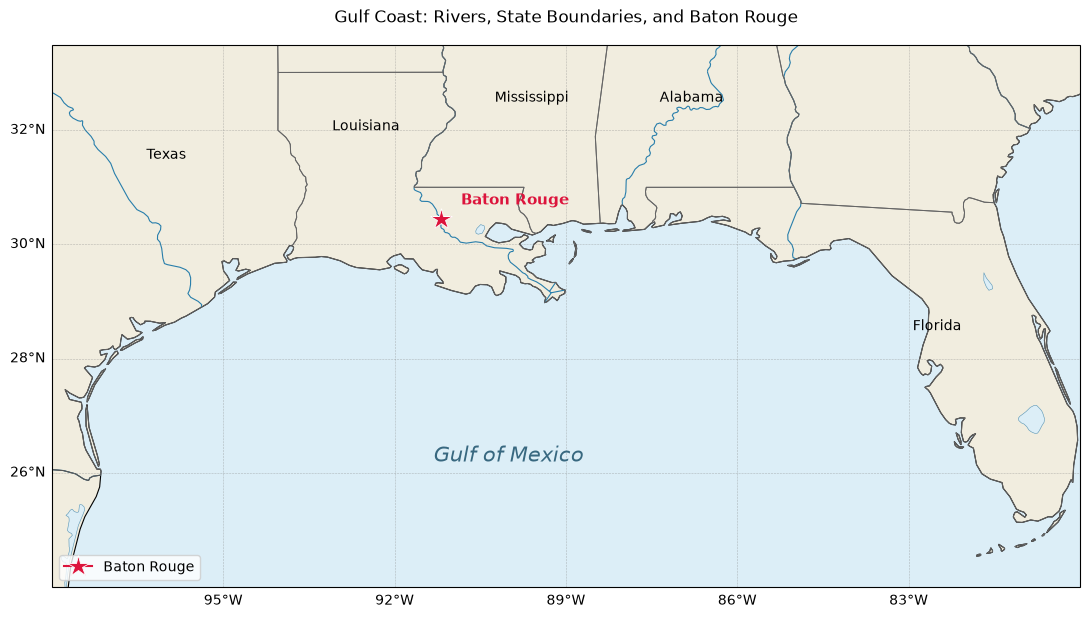

In [2]:
# Use a geographic projection and focus on the northern Gulf Coast.
projection = ccrs.PlateCarree()
fig = plt.figure(figsize=(11, 6.5))
ax = fig.add_subplot(1, 1, 1, projection=projection)
ax.set_extent([-98, -80, 24, 33.5], crs=projection)
ax.set_facecolor("#dceef7")

# Add land, coastlines, lakes, rivers, state boundaries, and national borders.
ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="#f1eddf", zorder=0)
ax.coastlines(resolution="50m", linewidth=0.8)
ax.add_feature(cfeature.LAKES.with_scale("50m"), facecolor="#dceef7", edgecolor="#5794b5", linewidth=0.4)
ax.add_feature(cfeature.RIVERS.with_scale("50m"), edgecolor="#287eab", linewidth=0.8)
ax.add_feature(cfeature.STATES.with_scale("50m"), edgecolor="#666666", linewidth=0.7)
ax.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="#555555", linewidth=0.7)

# Geographic plotting uses longitude first, then latitude.
baton_rouge_lon, baton_rouge_lat = -91.1871, 30.4515
ax.plot(baton_rouge_lon, baton_rouge_lat, marker="*", color="crimson",
        markeredgecolor="white", markeredgewidth=0.6, markersize=16,
        transform=projection, label="Baton Rouge", zorder=5)
ax.text(baton_rouge_lon + 0.35, baton_rouge_lat + 0.25, "Baton Rouge",
        transform=projection, fontsize=11, color="crimson", fontweight="bold")

# Label major states to make the map easier to read.
for name, lon, lat in [("Texas", -96, 31.5), ("Louisiana", -92.5, 32),
                       ("Mississippi", -89.6, 32.5), ("Alabama", -86.8, 32.5),
                       ("Florida", -82.5, 28.5)]:
    ax.text(lon, lat, name, ha="center", fontsize=10, transform=projection)
ax.text(-90, 26.2, "Gulf of Mexico", fontsize=15, fontstyle="italic",
        color="#386880", ha="center", transform=projection)

grid = ax.gridlines(draw_labels=True, linewidth=0.4, color="gray", alpha=0.5, linestyle="--")
grid.top_labels = False
grid.right_labels = False
grid.xlocator = FixedLocator(np.arange(-98, -79, 3))
grid.ylocator = FixedLocator(np.arange(24, 34, 2))
ax.set_title("Gulf Coast: Rivers, State Boundaries, and Baton Rouge", pad=16)
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig("W1_gulf_coast_9_2.png", dpi=180, bbox_inches="tight")
plt.show()


**W.2** Do some more work on the Chipotle data from Monday

Records: 4,622
Distinct orders: 1,834
Distinct item names: 50
Total units sold: 4,972
Total revenue: $34,500.16
Average order value: $18.81

Top five items by quantity sold:


,quantity_sold,revenue
item_name,,
Chicken Bowl,761,7342.73
Chicken Burrito,591,5575.82
Chips and Guacamole,506,2201.04
Steak Burrito,386,3851.43
Canned Soft Drink,351,438.75



Top five items by revenue:


,quantity_sold,revenue
item_name,,
Chicken Bowl,761,7342.73
Chicken Burrito,591,5575.82
Steak Burrito,386,3851.43
Steak Bowl,221,2260.19
Chips and Guacamole,506,2201.04


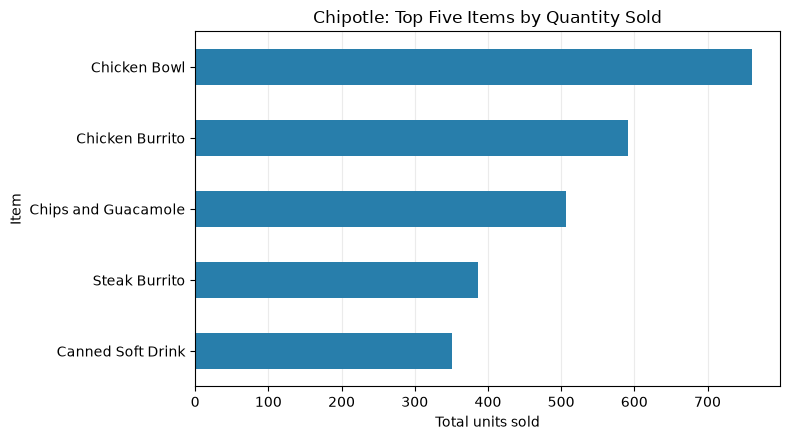

In [3]:
# Read the supplied dataset, using a local copy when available.
url = "https://raw.githubusercontent.com/justmarkham/DAT8/master/data/chipotle.tsv"
data_file = Path("data/chipotle.tsv")
if data_file.exists():
    chipo = pd.read_csv(data_file, sep="\t")
else:
    chipo = pd.read_csv(url, sep="\t")
    data_file.parent.mkdir(parents=True, exist_ok=True)
    chipo.to_csv(data_file, sep="\t", index=False)

# Convert the recorded line totals from currency strings to numbers.
chipo["item_price"] = (
    chipo["item_price"].str.replace("$", "", regex=False).str.strip().astype(float)
)

# Continue the Chipotle analysis with grouping, aggregation, and sorting.
# 1. Summarize the number of records, orders, and units sold.
number_of_orders = chipo["order_id"].nunique()
print(f"Records: {len(chipo):,}")
print(f"Distinct orders: {number_of_orders:,}")
print(f"Distinct item names: {chipo['item_name'].nunique()}")
print(f"Total units sold: {chipo['quantity'].sum():,}")

# 2. Calculate revenue per order and the average order value.
# item_price already includes quantity, so do not multiply it again.
order_totals = chipo.groupby("order_id")["item_price"].sum()
print(f"Total revenue: ${order_totals.sum():,.2f}")
print(f"Average order value: ${order_totals.mean():.2f}")

# 3. Find the five best-selling items by total quantity, not row count.
item_summary = chipo.groupby("item_name").agg(
    quantity_sold=("quantity", "sum"),
    revenue=("item_price", "sum"),
)
top_quantity = item_summary.sort_values("quantity_sold", ascending=False).head(5)
print("\nTop five items by quantity sold:")
display(top_quantity)

# 4. Compare the five largest revenue-generating items.
top_revenue = item_summary.sort_values("revenue", ascending=False).head(5)
print("\nTop five items by revenue:")
display(top_revenue)

# 5. Plot the best-selling items with the largest value at the top.
fig, ax = plt.subplots(figsize=(8, 4.5))
top_quantity["quantity_sold"].sort_values().plot.barh(ax=ax, color="#287eab")
ax.set_xlabel("Total units sold")
ax.set_ylabel("Item")
ax.set_title("Chipotle: Top Five Items by Quantity Sold")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig("W2_chipotle_top_items_9_2.png", dpi=180, bbox_inches="tight")
plt.show()

# Lecture 9.2

### Agenda:

- Questions
- Intro to Zotero

### Questions

# Lab 9.2

**E.0** Complete the previous labs if you are behind.

**E.1** Install Zotero and the plugins for your web browser (Chrome or Firefox suggested), Word, and Google docs. Use Zotero to grab a 2-3 citations from the web (e.g., from a scientific journal article web page), then cite them in both Word and Google docs in a sentance or two, then add a Bibliography using zotero.

In Moodle, turn in your word document, a screenshot of your google doc, and a screenshot of your zotero library.

**E.3** Complete your final project proposal and submit it in Moodle

**E.4** Prepare a 5 min presentation of your project proposal, including a brief introduction, your research plan, the programming methods you are planning to use, your preliminary results/plots, and your timeline for completion. ​You will present this in class next Monday.

A good target length is 1 slide per minute.

Upload your talk here: https://lsu.box.com/s/jc4x0p5mu7u1tst38m98i0t1e35z2mfl


**B.1** Bonus! Integrate zotero and overleaf. Note to have the zotero plugin for overleaf you have to pay them. However, you can export a .bib style bibliography for LaTeX and load it into overleaf. If you are extra, go for it! Submit a pdf of your LaTeX document with citations and bibliography, and a screenshot of your .bib file

**Notes** Make notes for yourself on progamming tecniques and commands you learned in the this week, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.